**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [37]:
import scez

scanpy==1.9.1 anndata==0.8.0 umap==0.5.3 numpy==1.22.4 scipy==1.9.0 pandas==1.4.3 scikit-learn==1.1.2 statsmodels==0.13.2 python-igraph==0.9.11 pynndescent==0.5.7


In [5]:
from utils import *

In [6]:
from upsetplot import from_contents, UpSet

In [7]:
def add_marker_feature(adata,marker,marker_name,clusters_name,thr = 0,figsize=(10,4)):

    df = pd.concat([
        adata.obs.groupby([marker_name,clusters_name]).size()[f'{marker}+'],
        adata.obs.groupby([marker_name,clusters_name]).size()[f'{marker}-']
    ],axis=1).rename(columns={0:f'{marker}+',1:f'{marker}-'})
    
    # Make some labels.
    labels = df[f'{marker}+'] / df.sum(axis=1) * 100
    labels = labels.round(decimals=1)
    labels.sort_values(ascending=False,inplace=True)
    df = df.loc[labels.index,]
    
    ax = df.plot.bar(stacked=True,rot=0,figsize=figsize)

    rects = ax.patches

    for rect, label in zip(rects, labels):
        height = rect.get_height()
        ax.text(
            rect.get_x() + rect.get_width() / 2, height + 5, str(label) + "%", 
            ha="center", va="bottom", fontsize=8
        )

    ax.set_yscale('log')
    ax.set_ylabel('# of cells')
    return ax


## marker genes for neuronal/non-neuronal cells

In [76]:
cell_types = {
    "non-neuronal cells":[
        "Endothelial","Oligodentrocyte",
        # "OPCs", # oligodendrocyte progenitor cells 
        "Microglia","astrocytes",
        # "neuroblast"
        # "interneuron",
    ],

    # "neuron":[
    #     # "neuron main markers",
    #     # "GABAergic",
    #     # "glutamatergic",
    #     # "D1 MSN",
    #     # "D2 MSN (Ppp1r1b+ medial spiny neuron)",
    #     # "D1H",
    #     # "ICj"
    # ]
}

In [195]:
marker_genes = {
    "Endothelial": ["Cldn5","Ptprb"],
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":['Slc1a3','Gja1'], #"Aqp4",
}

In [196]:
neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type in cell_types['neuron']
}

not_neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type not in cell_types['neuron']
}

## Load data 
`adata` -> `scvi` denoised and then clustered

In [293]:
results_file = 'preprocessing/adata-denoised-clustered-v2.h5ad.gz'

adata = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [294]:
del adata.raw, adata.var, adata.uns, adata.varm, adata.obsp

for col in adata.obs.columns[adata.obs.columns.str.startswith('_')]: 
    del adata.obs[col]

In [295]:
adata.var_names_make_unique()

In [296]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

### Label Neuron

In [297]:
leiden_list = []
for l in adata.obs.leiden_scVI:
    if int(l) in [0,1,2,5,7,12,
                  #13,
                  14,15,
                  19,20,21,22,23,24,25]: leiden_list.append('Neuron')
    else: leiden_list.append(l)

adata.obs['label'] = pd.Categorical(leiden_list)

In [298]:
d = pd.DataFrame(adata.obs['label'] == 'Neuron').groupby('label').size()

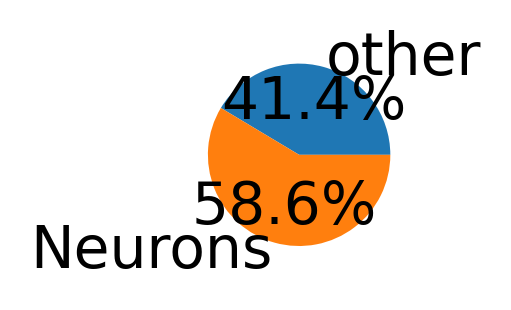

In [299]:
fig = plt.figure(figsize =(1, 1),dpi=150)
plt.pie(d.values,labels=['other','Neurons'],autopct='%1.1f%%')
# show plot
plt.show()

## Split dataset

In [300]:
adata_neuron = adata[adata.obs.label == 'Neuron'].copy()

In [301]:
adata_non_neuron = adata[adata.obs.label != 'Neuron'].copy()

# Neurons

### sub-clustering

In [302]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [303]:
adata_neuron

AnnData object with n_obs × n_vars = 12663 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

In [304]:
sc.tl.pca(adata_neuron)

In [314]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_neuron, use_rep="X_scVI")
sc.tl.umap(adata_neuron, min_dist=0.1)

In [318]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_neuron, key_added="leiden_neuron", resolution=0.1)

#### Scale

In [319]:
adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

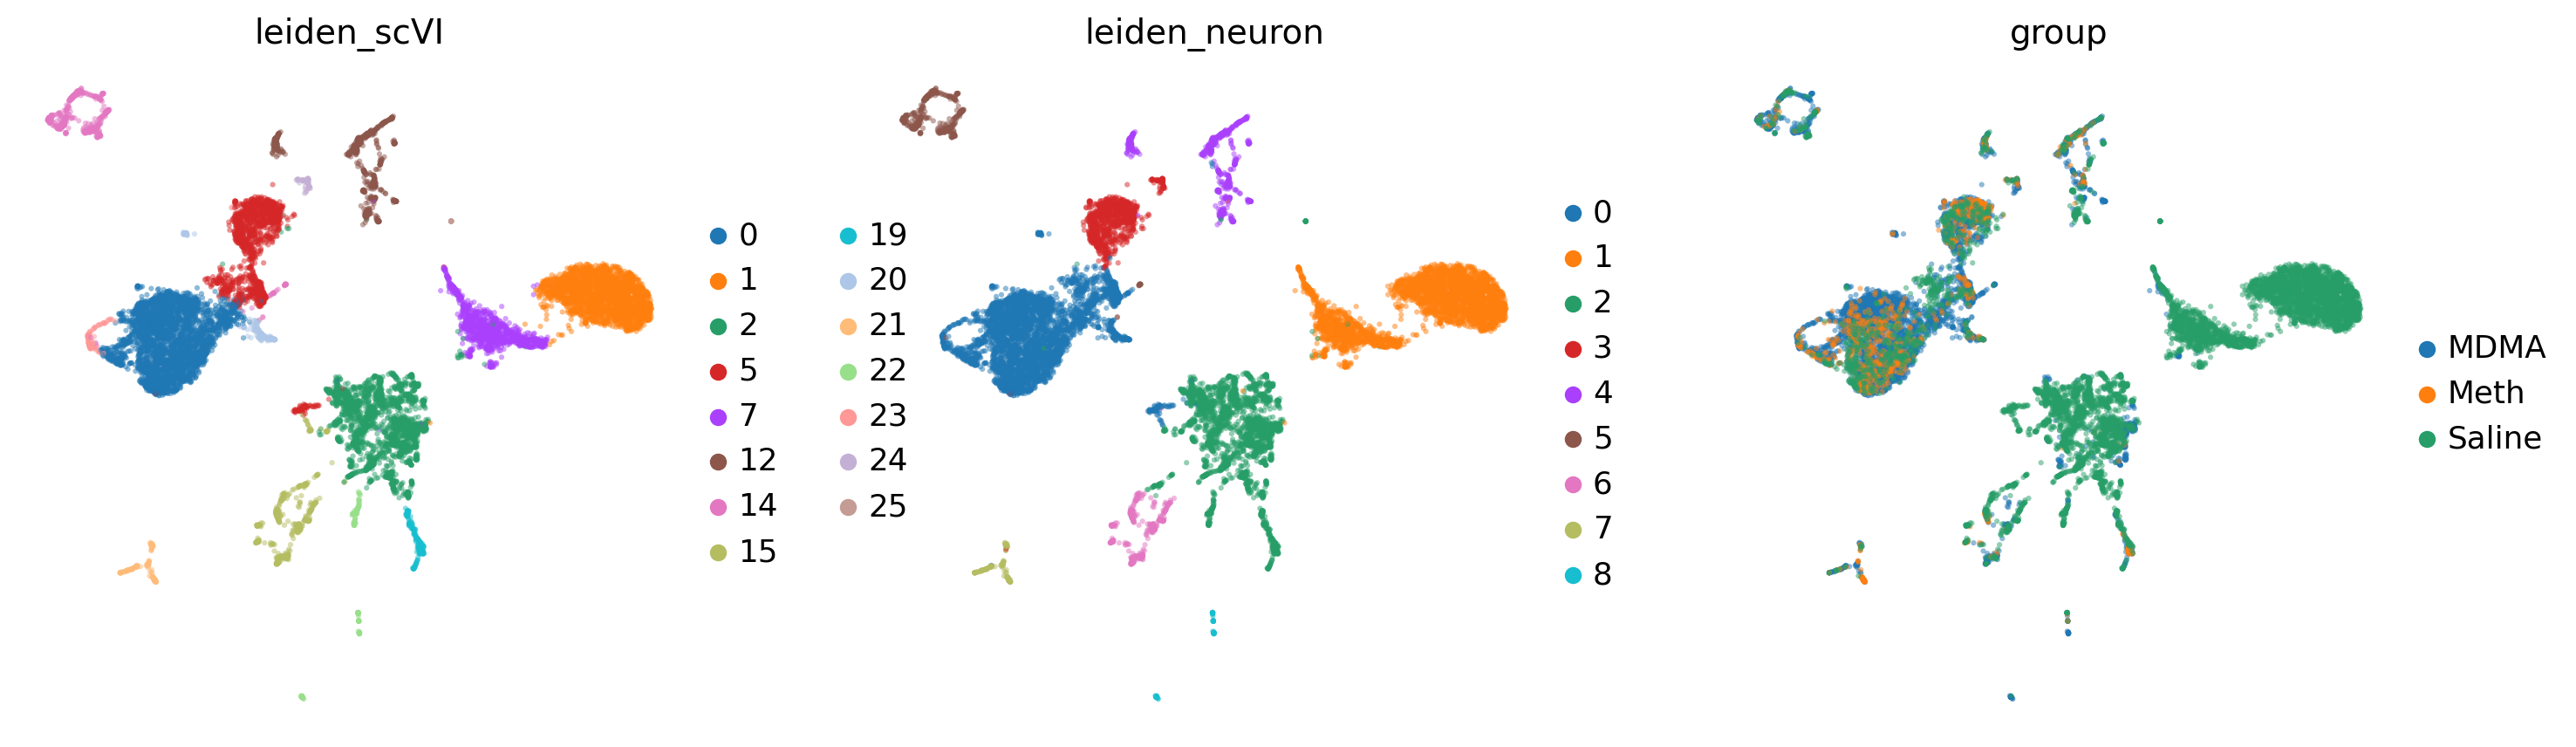

‘figures/umap_neuron.pdf’ -> ‘celltyping/neuron_umap.pdf’


In [403]:
sc.pl.umap(
    adata_neuron,
    color=[
        # "Snap25","Sox11",
        # "Gad1", # (GABAergic marker) 
        # # "Slc17a6", "Slc17a7", # glutamatergic marker
        # "Resp18", # interneuron marker
        # "Ppp1r1b",# MSN marker 
        # "Ptgds","Dlx1",
        
        "leiden_scVI",
        'leiden_neuron',
        'group',
    ],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    layer='scaled',
    # legend_loc='on data',
    # add_outline=0.1
    save = '_neuron'
)

!mv -v figures/umap_neuron.pdf celltyping/neuron_umap.pdf

In [309]:
# sc.pl.umap(
#     adata_neuron,
#     color=['Snap25','Sox11','Grin3a','Apod',#'Gria1',
#            'Gt(ROSA)26Sor',
#            'group',"leiden_scVI",'leiden_neuron'],
#     vmax=1,
#     vmin=0,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=10,
#     # legend_loc='on data',
#     # add_outline=0.1
# )

In [310]:
# sc.pl.umap(
#     adata_neuron,
#     color=[
#         'group','leiden_neuron'
#     ],
#     vmin=0,vmax=1,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=10,
#     # legend_loc='on data',
#     # add_outline=0.1
# )

### Conditions within sub-clusters

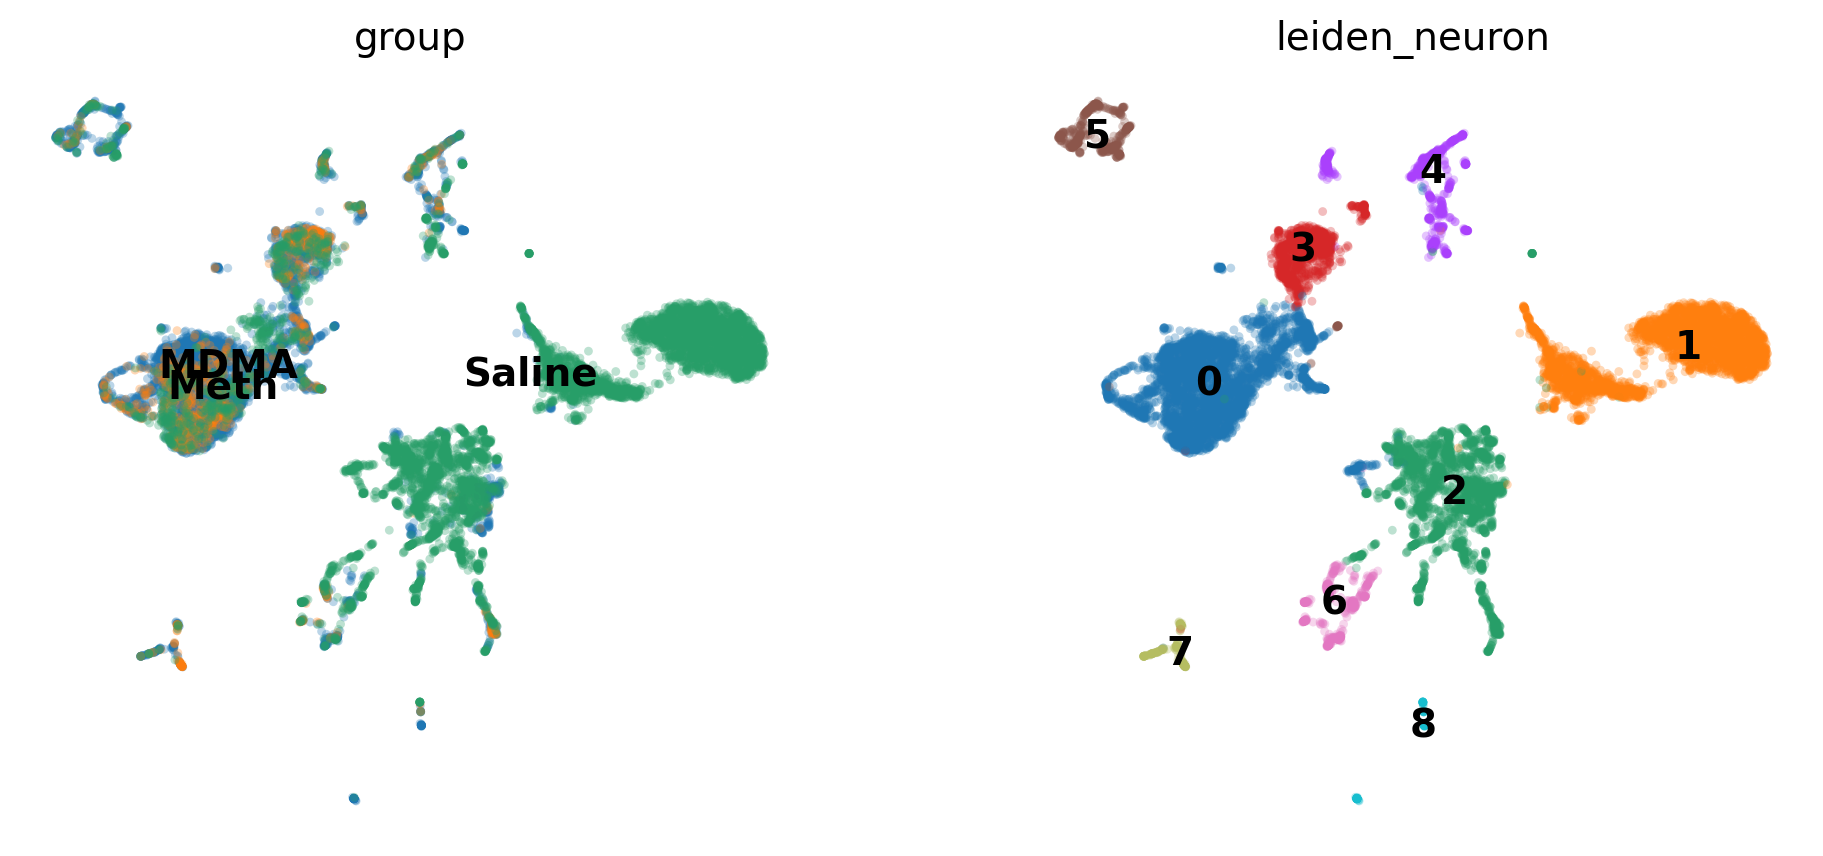

In [321]:
sc.pl.umap(
    adata_neuron,
    color=[
        'group','leiden_neuron'
    ],
    vmin=0,vmax=1,
    color_map="Reds",
    frameon=False,alpha=0.3,size=40,
    legend_loc='on data',
    # add_outline=0.1
)

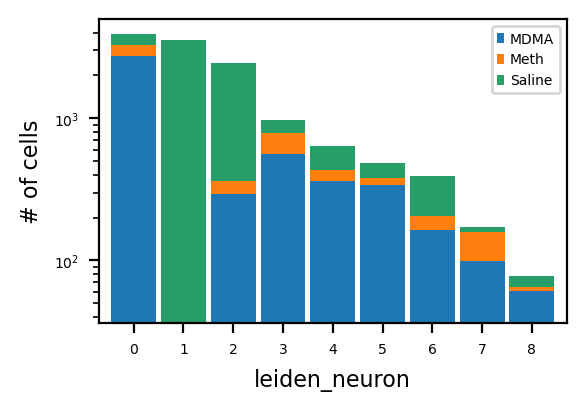

In [322]:
df = pd.DataFrame(adata_neuron.obs.groupby(['group','leiden_neuron']).size()).reset_index().pivot(
    index='group', columns='leiden_neuron', values=0
).T

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('# of cells',fontsize=8)
ax.set_xlabel('leiden_neuron',fontsize=8)
ax.grid(False)
ax.set_yscale('log')

plt.legend(loc='upper right', 
           # bbox_to_anchor=(1.2, 0.5),
           fontsize=5)
plt.show()

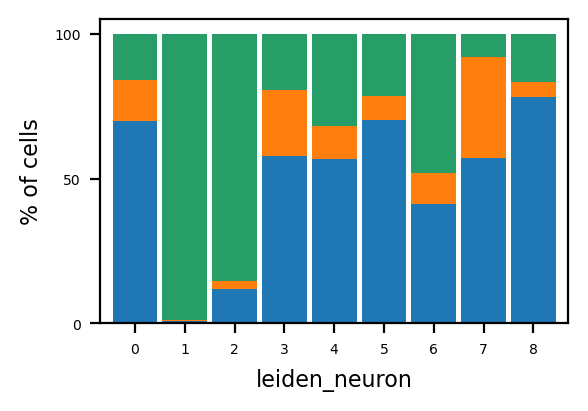

In [323]:
df = pd.DataFrame(adata_neuron.obs.groupby(['group','leiden_neuron']).size()).reset_index().pivot(
    index='group', columns='leiden_neuron', values=0
).T
df = df.div(df.sum(axis=1), axis=0) * 100

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('% of cells',fontsize=8)
ax.set_xlabel('leiden_neuron',fontsize=8)
ax.grid(False)
ax.get_legend().remove()

plt.show()

### Rank genes within sub-clusters

In [324]:
sc.tl.rank_genes_groups(
    adata_neuron, 'leiden_neuron', method='t-test'
)

In [325]:
def revert_upset_dataframe(up_data):
    return up_data.reset_index().set_index('id')

def get_intersection(up_data,which='all'):
    df = revert_upset_dataframe(up_data)
    if which == 'all':
        df = df[df.sum(axis=1) == 1]
        l = list()
        for col in df.columns:
            l.append((col, df.index[df[col]].tolist()))
            
        out = pd.DataFrame(l,columns=['cluster_vs_all','unique_ranked_genes'])
        out.unique_ranked_genes = out.unique_ranked_genes.str.join(',')
            
    else:
        out = pd.DataFrame(
        {
            'cluster_vs_all':which,
            'unique_ranked_genes':[','.join(df.index[df[which.split(',')].sum(axis=1)==2])]
        }
    )

    return out

In [424]:
top_ranked_neuron_clusters_full = rank_genes_to_df(
    adata_neuron, n = 20
)
top_ranked_neuron_clusters = top_ranked_neuron_clusters_full.filter(regex='names')

In [425]:
top_ranked_neuron_clusters.iloc[:20,]

,0_names,1_names,2_names,3_names,4_names,5_names,6_names,7_names,8_names
0,Ptprz1,Ptgds,Flt1,Malat1,Fyn,Stmn1,Myl9,Meg3,Hbb-bs
1,Lhfpl3,Ccl4,Cldn5,Gm26917,Bcas1,Hmgn2,Cald1,Nrxn3,Hba-a1
2,Cspg5,Hbb-bs,Ly6c1,Snrnp70,Sirt2,Tubb5,Rgs5,Rian,Hba-a2
3,Pdgfra,Mal,Klf4,Usp24,Plp1,Ccnd2,Igfbp7,Syt1,Hbb-bt
4,Serpine2,Cst3,Cxcl12,Gria2,Epb41l2,Sox11,Mylk,Celf4,Mbp
5,Olig1,Plp1,Slco1a4,Pnisr,Slc44a1,Tmsb10,Crip1,Ttc3,Alas2
6,Cntn1,Klf2,Pltp,Ankrd11,Map1b,Hnrnpa1,Tpm2,Gria1,Car2
7,Cdo1,Bsg,Junb,Meg3,Enpp6,Hmgb3,Filip1l,Grin2b,Mal
8,Luzp2,Mag,Bsg,Dst,Cnp,Jpt1,Myh11,Atp1b1,Mobp
9,Ednrb,Ly6c1,Selenop,Mycbp2,Mpzl1,Tuba1a,Tagln,Gm26917,Isg20


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/upsetplot/plotting.py:805: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  colors = pd.Series([


IndexError: index -1 is out of bounds for axis 0 with size 0

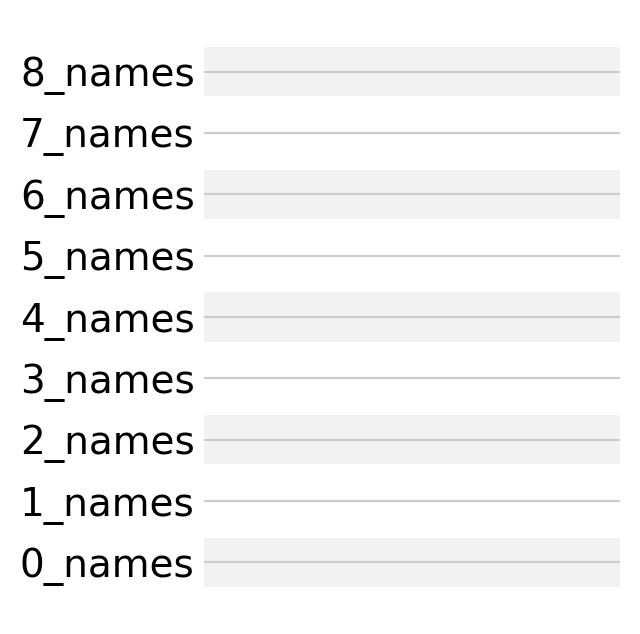

In [426]:
upset = UpSet(
    from_contents(top_ranked_neuron_clusters),
    # min_degree=2, 
    subset_size='count',
    min_subset_size=25, 
    show_counts=True,
).plot()

plt.savefig('celltyping/top_ranked_neuron_clusters_largest.pdf',font_size=10)

/tmp/ipykernel_123926/3003512647.py:9: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "font_size" which is no longer supported as of 3.3 and will become an error in 3.6
  plt.savefig('celltyping/top_ranked_neuron_clusters_all.pdf',font_size=10)


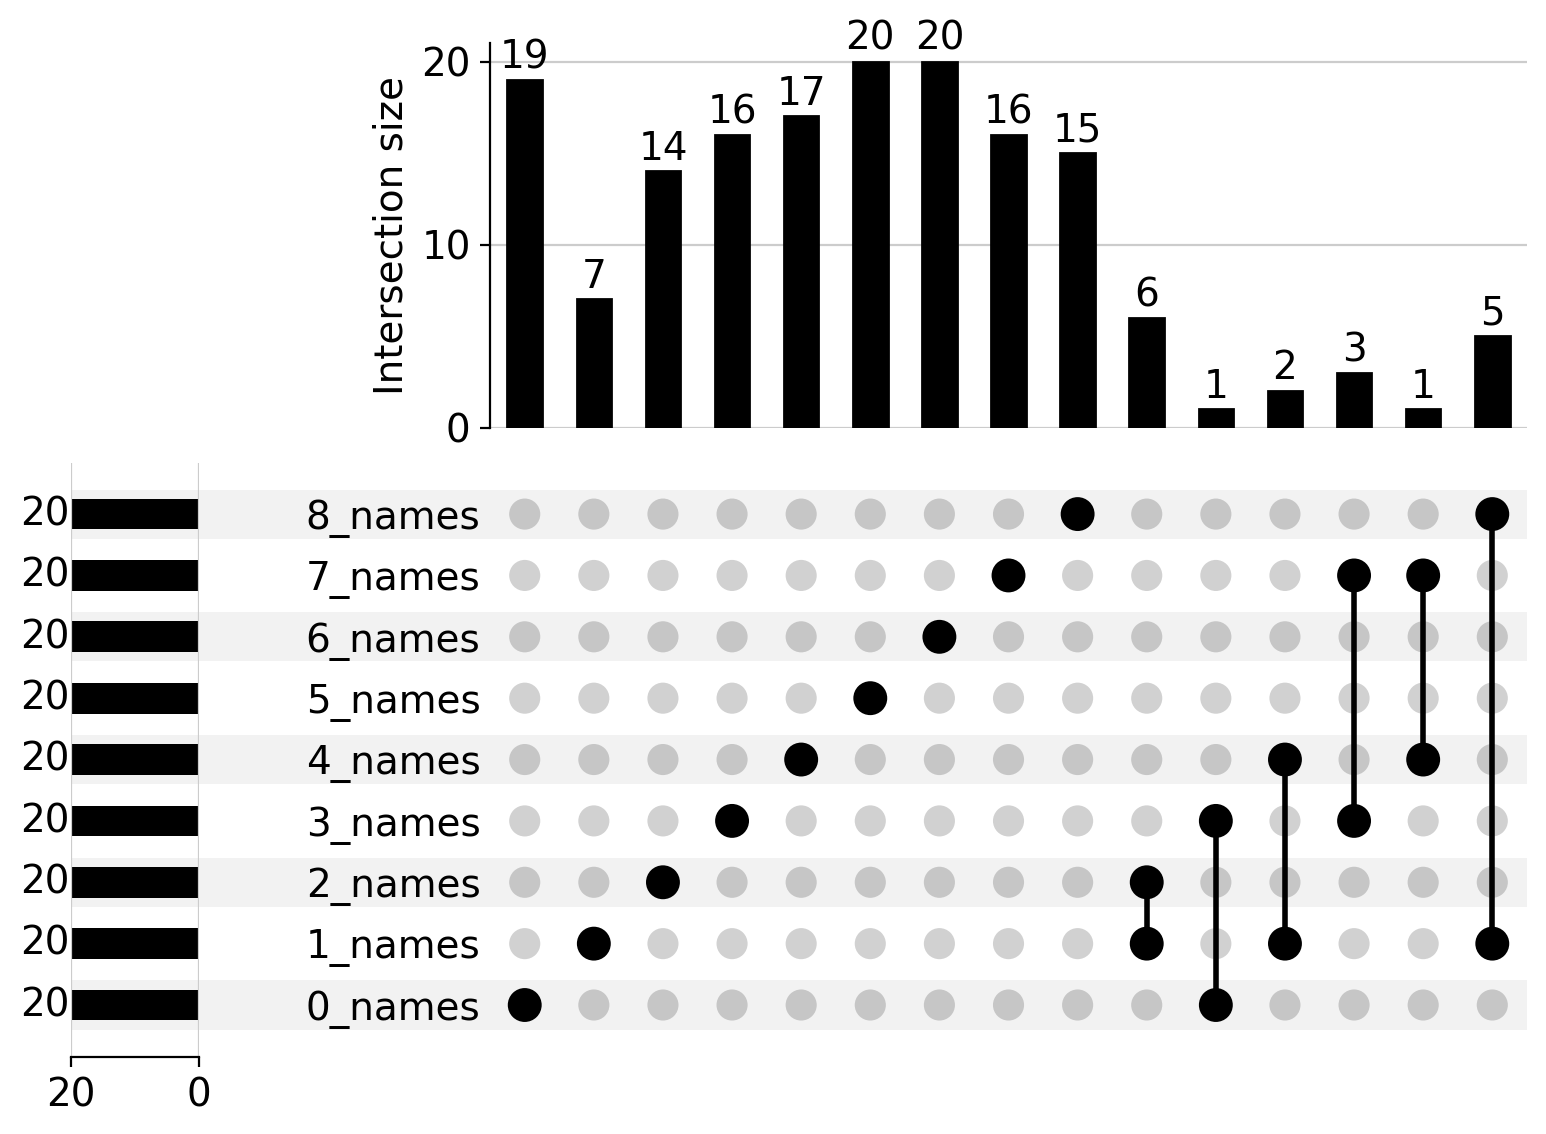

In [427]:
upset = UpSet(
    from_contents(top_ranked_neuron_clusters),
    # min_degree=2, 
    subset_size='count',
    # min_subset_size=25, 
    show_counts=True,
).plot()

plt.savefig('celltyping/top_ranked_neuron_clusters_all.pdf',font_size=10)

In [428]:
top_ranked_neuron_clusters_rev = revert_upset_dataframe(
    from_contents(top_ranked_neuron_clusters)
)

In [432]:
clusters_unique_ranked_genes = pd.concat([
    get_intersection(from_contents(top_ranked_neuron_clusters)),
    # get_intersection(from_contents(top_ranked_neuron_clusters),which='7_names,13_names,0_names'),
    # get_intersection(from_contents(top_ranked_neuron_clusters),which='13_names,9_names'),
    # get_intersection(from_contents(top_ranked_neuron_clusters),which='0_names,7_names'),
    # get_intersection(from_contents(top_ranked_neuron_clusters),which='14_names,4_names'),
    # get_intersection(from_contents(top_ranked_neuron_clusters),which='5_names,2_names'),
])

In [441]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
writer = pd.ExcelWriter('celltyping/top_ranked_neuron_clusters-v2.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
top_ranked_neuron_clusters_full.to_excel(writer, sheet_name='full')
clusters_unique_ranked_genes.set_index('cluster_vs_all').to_excel(writer, sheet_name='clusters_unique_ranked_genes')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

### 
___

In [338]:
sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [339]:
adata_neuron

AnnData object with n_obs × n_vars = 12663 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label', 'leiden_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_scVI_colors', 'leiden_neuron_colors', 'group_colors', 'rank_genes_groups', 'dendrogram_leiden_neuron'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized', 'scaled'
    obsp: 'distances', 'connectivities'

In [341]:
# name = 'top_ranked_neuron_clusters'

# ax = sc.pl.dotplot(
#     adata_neuron, 
#     dict([(clust,genes.split(',')[:10]) for clust,genes in clusters_unique_ranked_genes.values]),
#     groupby=['leiden_neuron'], 
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     save = name
# )

# !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [343]:
# # name = 'top_ranked_neuron_clusters'

# ax = sc.pl.dotplot(
#     adata_neuron, 
# dict([(clust,genes.split(',')[:5]) for clust,genes in clusters_unique_ranked_genes.values
#       if clust in ['5_names,2_names','14_names,4_names']]),
#     groupby=['leiden_neuron'],
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     # save = name
# )

# # !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [344]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [345]:
# ax = sc.pl.dotplot(
#     adata_neuron, 
#     [gene for clust,genes in temp for gene in genes],# if clust in ['8_names','5_names','0_names',
#                                                                     # '1_names','2_names','4_names']], 
#     groupby=['leiden_neuron'], 
#     swap_axes=False, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     # layer='scaled', 
#     vmin=-4, vmax=4, cmap='RdBu_r',
#     # save = 'Snap25_neg'
# )

# # !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

### Save to file

Here, we need to think more about how to find subclusters!

In [346]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron.write_h5ad(results_file)

# Non-Neurons

In [362]:
adata_non_neuron

AnnData object with n_obs × n_vars = 8951 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

#### Scale

In [363]:
adata_non_neuron.layers['scaled'] = sc.pp.scale(adata_non_neuron, copy=True).X

In [364]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [365]:
sc.tl.pca(adata_non_neuron)

In [366]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)

In [367]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.1)

In [368]:
sc.tl.dendrogram(adata_non_neuron,'leiden_non_neuron') 

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Oligodentrocyte, Microglia, etc.


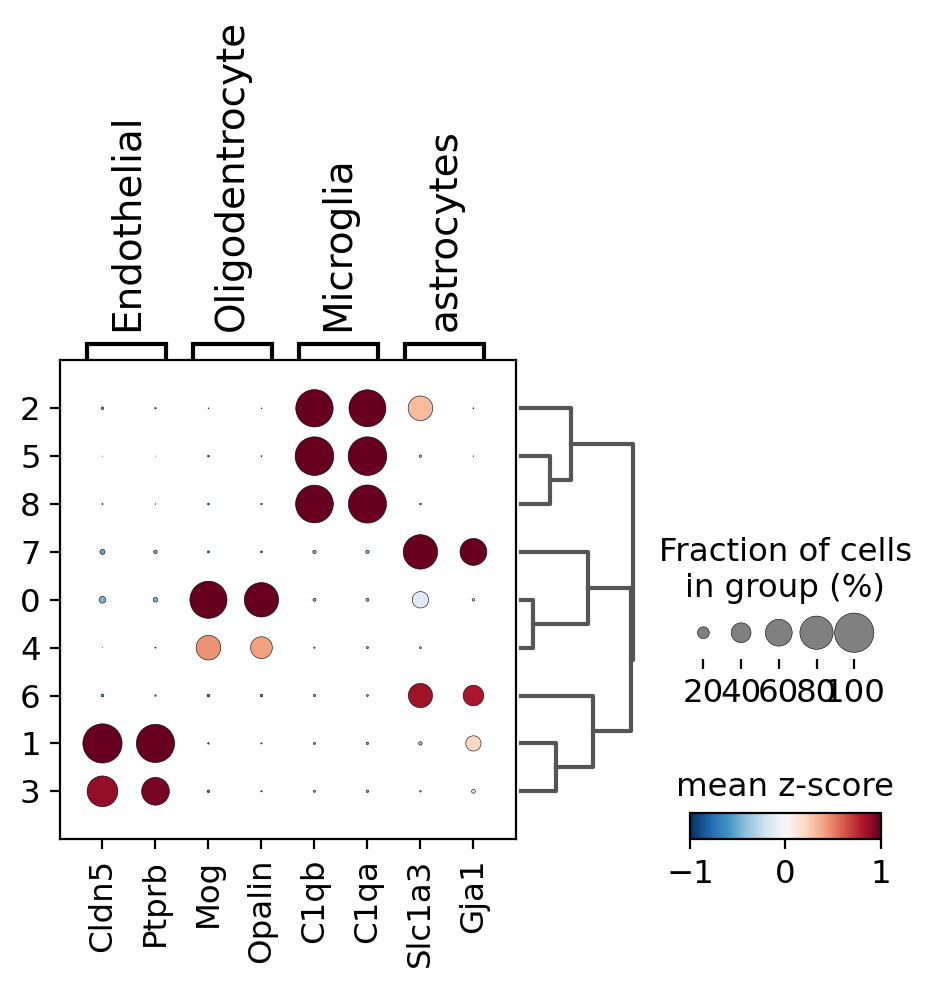

In [371]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['leiden_non_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [370]:
# sc.pl.umap(
#     adata_non_neuron,
#     color=[
#         # 'label',
#         'leiden_scVI',
#         'leiden_non_neuron',
#         # "Mog","Ptprb",
#         "Snap25",'Sox11',
#         "Apod",
#         # 'group',
#     ] + [gene for k in not_neuron_genes for gene in not_neuron_genes[k]],
#     vmax=2,
#     vmin=0,
#     layer='scaled', 
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=30,
#     legend_loc='on data',
#     add_outline=0.1,
#     save = '_non_neuron'
# )

# !mv -v figures/umap_non_neuron.pdf celltyping/non_neuron_umap.pdf

In [372]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    # - Microglia: 8, 5, 2
    if int(l) in [2,5,8]: leiden_list.append('Microglia')
    # - Astrocyte: 6, 7
    elif int(l) in [6,7]: leiden_list.append('Astrocytes')
    # - Endothelial: 1, 3
    elif int(l) in [1,3]: leiden_list.append('Endothelial')
    # - Oligodentrocyte: 0, 4
    elif int(l) in [0,4]: leiden_list.append('Oligodendrocytes')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [373]:
sc.tl.dendrogram(adata_non_neuron,'label') 

categories: Astrocytes, Endothelial, Microglia, etc.
var_group_labels: Endothelial, Oligodentrocyte, Microglia, etc.


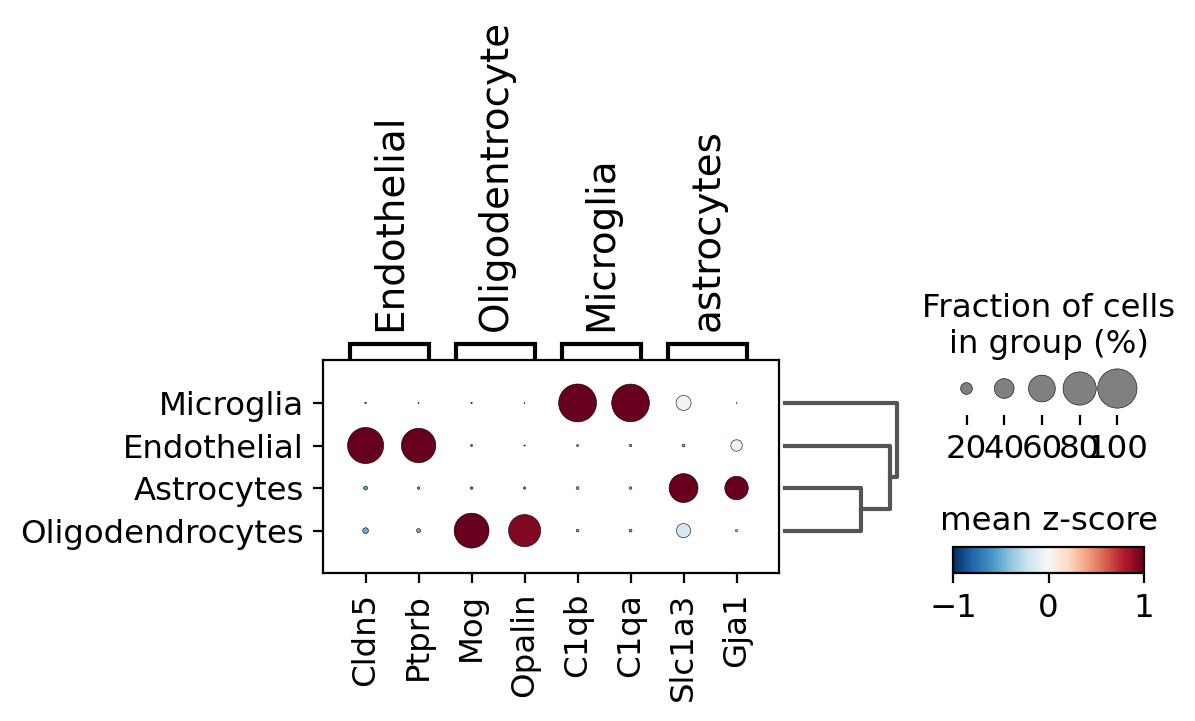

In [374]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['label'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

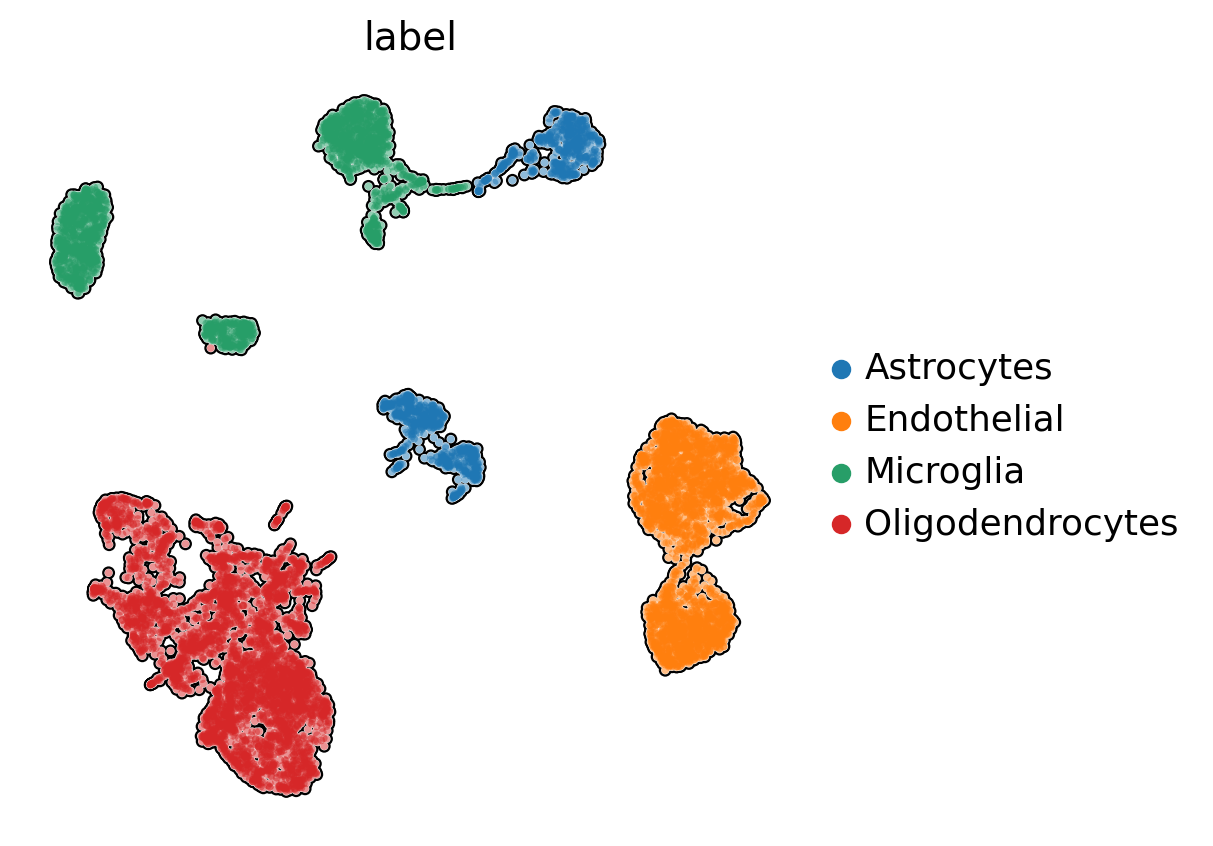

In [375]:
sc.pl.umap(
    adata_non_neuron,
    color=[
        'label',
        # 'leiden_scVI',
        # 'leiden_non_neuron',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        # 'group',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

In [376]:
sc.tl.rank_genes_groups(adata_non_neuron, 'label', 
                        n_genes=adata_non_neuron.shape[1], method='t-test'
                       )

In [378]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_non_neuron, 
#     # groupby=['label'],
#     n_genes=5,
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     # groups=['12','10','6','9'],
#     vmin=-8, vmax=8, cmap='RdBu_r',
# )

In [379]:
non_neuron_ranks = rank_genes_to_df(adata_non_neuron, n = 50)
# non_neuron_ranks
# Snap25_pos_rankdf.to_csv('celltyping/Snap25_pos_rank_genes.csv',index=False)

In [ ]:
# non_neuron_ranks

##### 
save :)

In [380]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron.write_h5ad(results_file)

___

In [381]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = sc.read_h5ad(results_file)

In [389]:
# ax = add_marker_feature(adata_non_neuron,marker='Sox11',marker_name='Sox11 label',clusters_name='label',figsize=(4,3))

# plt.savefig('celltyping/percent_in_leiden_non_neuron_Sox11.pdf')

In [390]:
# ax = add_marker_feature(adata_non_neuron,marker='Snap25',marker_name='Snap25 label',clusters_name='label',figsize=(4,3))

# plt.savefig('celltyping/percent_in_leiden_non_neuron_Snap25.pdf')

# All data

In [404]:
adata.obs['final label'] = ''

adata.obs.loc[adata_neuron.obs_names,'final label'] = 'neuron'#list(adata_neuron.obs.leiden_neuron)
adata.obs.loc[adata_non_neuron.obs_names,'final label'] = list(adata_non_neuron.obs.label)

adata.obs['final label'] = pd.Categorical(list(adata.obs['final label']))

In [405]:
# adata.obs.loc[adata_neuron.obs_names,'leiden_neuron'] = list(adata_neuron.obs.leiden_neuron)
# adata.obs['leiden_neuron'] = pd.Categorical(list(adata.obs['leiden_neuron']))

#### scale

In [406]:
adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

In [421]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata, min_dist=0.1)

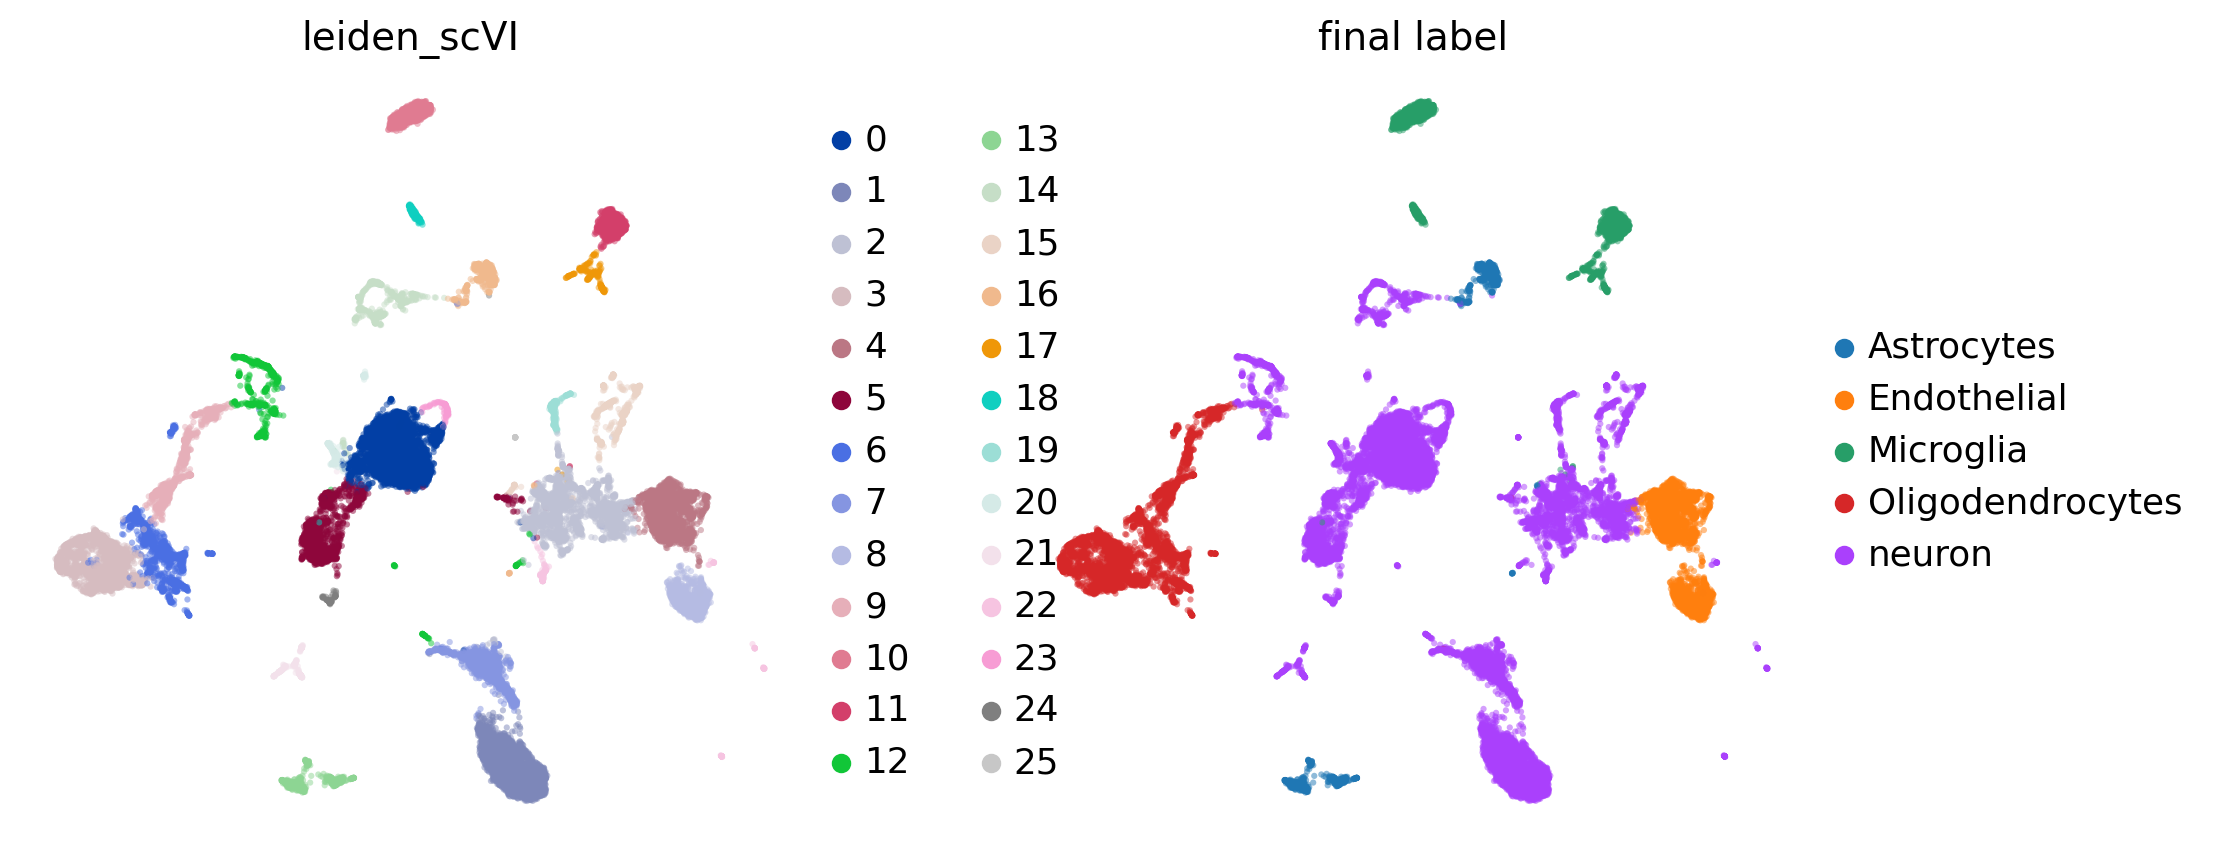

‘figures/umap_20221115.pdf’ -> ‘celltyping/umap_20221115.pdf’


In [422]:
sc.pl.umap(
    adata,
    color=[
        # 'group',
        'leiden_scVI',
        # 'leiden_neuron',
        # "Sox11 label",
        # 'Snap25 label',
        'final label',
        # "Sox11",'Snap25',
    ],
    vmax=.1,vmin=-.1,
    layer='scaled',
    color_map="Reds",
    frameon=False,
    alpha=0.5,size=20,
    # legend_loc='on data',
    # add_outline=0.01,
    save = '_20221115'
)

!mv -v figures/umap_20221115.pdf celltyping/

# 

In [61]:
!date

Fri Nov 11 15:31:33 PST 2022
